# Morphological Image Processing

Dilation, Erosion, Opening, and Closing using OpenCV. This notebook is a **reproducible demonstration using an example input image**. The previously written assignment source is preserved in `original_morphology.py` (which lets you upload your own image in Colab).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Path("results").mkdir(exist_ok=True)


## 1. Example image and binarization

The example image contains large objects, small gaps/holes and isolated foreground noise. We apply Otsu thresholding as in the original assignment.

Otsu threshold: 35.0


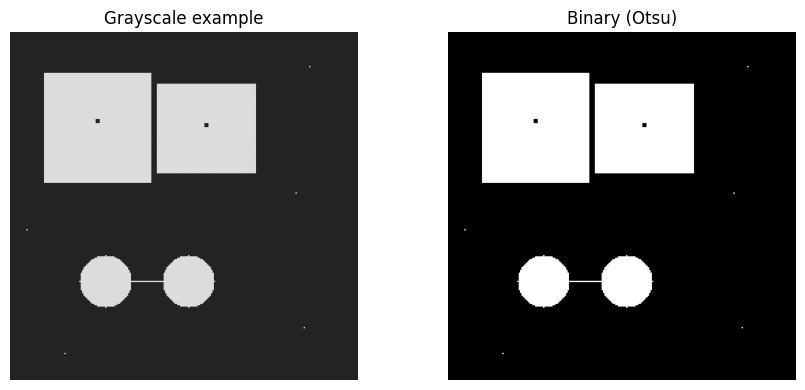

In [2]:
# Create a simple example grayscale image so the notebook runs without manual uploads.
img = np.full((256, 256), 35, dtype=np.uint8)
cv2.rectangle(img, (25, 30), (103, 110), 220, -1)
cv2.rectangle(img, (108, 38), (180, 103), 220, -1)
# Small holes in foreground objects
cv2.rectangle(img, (63, 64), (65, 66), 35, -1)
cv2.rectangle(img, (143, 67), (145, 69), 35, -1)
# Two circular foreground objects connected by a thin bridge
cv2.circle(img, (70, 183), 19, 220, -1)
cv2.circle(img, (131, 183), 19, 220, -1)
cv2.line(img, (89, 183), (112, 183), 220, 1)
# Small isolated foreground noise
for x, y in [(12, 145), (220, 25), (210, 118), (216, 217), (40, 236)]:
    img[y, x] = 220

threshold, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
cv2.imwrite("example_input.png", img)
print("Otsu threshold:", threshold)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, arr, title in zip(axes, [img, binary], ["Grayscale example", "Binary (Otsu)"]):
    ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Dilation and Erosion

Use the same 5 × 5 square structuring element as the earlier assignment.

In [3]:
SE = np.ones((5, 5), dtype=np.uint8)
dilation = cv2.dilate(binary, SE, iterations=1)
erosion = cv2.erode(binary, SE, iterations=1)
print("Structuring element (SE):")
print(SE)

Structuring element (SE):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


## 3. Opening and Closing

Opening = Erosion → Dilation. Closing = Dilation → Erosion.

In [4]:
opened_erosion = cv2.erode(binary, SE, iterations=1)
opening = cv2.dilate(opened_erosion, SE, iterations=1)

closed_dilation = cv2.dilate(binary, SE, iterations=1)
closing = cv2.erode(closed_dilation, SE, iterations=1)

## 4. Comparison of results

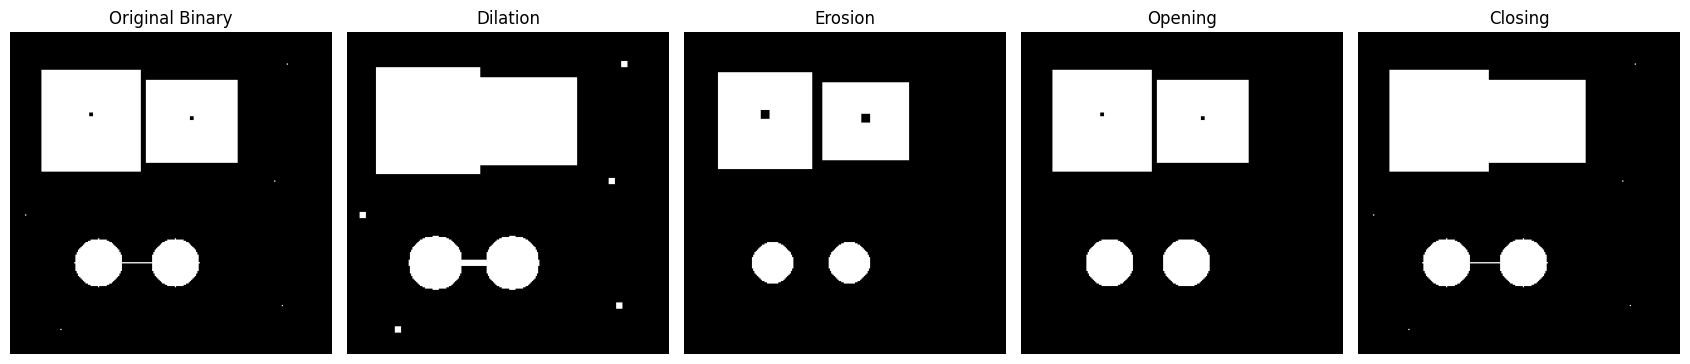

In [5]:
images = [binary, dilation, erosion, opening, closing]
titles = ["Original Binary", "Dilation", "Erosion", "Opening", "Closing"]
fig, axes = plt.subplots(1, 5, figsize=(17, 4.2))
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/morphology_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

## 5. Brief observations

- **Dilation:** expands white foreground areas and can connect close objects.
- **Erosion:** shrinks foreground areas and can remove thin connections.
- **Opening:** removes tiny foreground objects by erosion followed by dilation.
- **Closing:** can fill small background holes and narrow gaps.

The output above was produced with the **example image created in this notebook**, not the original manually uploaded photo.